Setup, Preprocessing, and Training (Uses GPU 🚀)
This single cell handles everything required to get a trained model. It will unzip the data, run the fast preprocessing, build the model architecture from your previous successful test, and train it.

In [ ]:
# === PART 1: UNZIP AND PREPROCESS ===
!unzip -oq dataset.zip
import cv2
import os
import tensorflow as tf

# Use the FAST Haar Cascade detector
face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')
TARGET_SIZE = (96, 96)

def detect_and_extract_fast(image_path):
    try:
        img = cv2.imread(image_path)
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        faces = face_cascade.detectMultiScale(gray, 1.1, 4)
        if len(faces) > 0:
            x, y, w, h = faces[0]
            face_roi = img[y:y+h, x:x+w]
            resized_face = cv2.resize(face_roi, TARGET_SIZE)
            return resized_face
        else: return None
    except Exception: return None

SOURCE_DIR = '.'; PROCESSED_DIR = 'processed_dataset'
os.makedirs(PROCESSED_DIR, exist_ok=True)
processed_count, skipped_count = 0, 0
print("Starting FAST dataset preprocessing...")
emotion_folders = ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
for class_name in emotion_folders:
    class_path = os.path.join(SOURCE_DIR, class_name)
    processed_class_path = os.path.join(PROCESSED_DIR, class_name)
    if not os.path.isdir(class_path): continue
    os.makedirs(processed_class_path, exist_ok=True)
    for image_name in sorted(os.listdir(class_path)):
        preprocessed_face = detect_and_extract_fast(os.path.join(class_path, image_name))
        if preprocessed_face is not None:
            cv2.imwrite(os.path.join(processed_class_path, image_name), preprocessed_face)
            processed_count += 1
        else: skipped_count += 1
print(f"\n\n--- PREPROCESSING COMPLETE ---\nProcessed: {processed_count} | Skipped: {skipped_count}\n----------------------------")


# === PART 2: BUILD AND TRAIN THE MODEL ===
from tensorflow.keras import layers, Model, backend as K
from tensorflow.keras.applications import MobileNetV2

# 1. Load Data
IMG_SIZE = 96; BATCH_SIZE = 32; AUTOTUNE = tf.data.AUTOTUNE
full_ds = tf.keras.utils.image_dataset_from_directory(
    PROCESSED_DIR, label_mode='int', image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE)
class_names = full_ds.class_names
DATASET_SIZE = tf.data.experimental.cardinality(full_ds).numpy()
train_size = int(0.8 * DATASET_SIZE)
val_ds = full_ds.skip(train_size)
train_ds = full_ds.take(train_size)
train_ds = train_ds.cache().prefetch(AUTOTUNE); val_ds = val_ds.cache().prefetch(AUTOTUNE)

# 2. Define Custom Layers from your successful test
class CoordinateAttention(layers.Layer):
    def __init__(self, r=32, **kwargs): super().__init__(**kwargs); self.r=r
    def build(self, input_shape):
        self.shared_layer_one = layers.Dense(input_shape[-1]//self.r, activation='relu', use_bias=False)
        self.shared_layer_two = layers.Dense(input_shape[-1], use_bias=False)
    def call(self, inputs):
        x_h=K.mean(inputs,axis=2,keepdims=True); x_w=K.mean(inputs,axis=1,keepdims=True)
        x_w=K.permute_dimensions(x_w,(0,2,1,3)); y=K.concatenate([x_h,x_w],axis=2)
        y=self.shared_layer_one(y); x_h,x_w=tf.split(y,2,axis=2)
        x_w=K.permute_dimensions(x_w,(0,2,1,3)); a_h=K.sigmoid(self.shared_layer_two(x_h)); a_w=K.sigmoid(self.shared_layer_two(x_w))
        return inputs*a_h*a_w
class STN(layers.Layer):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        self.localization_net = tf.keras.Sequential([
            layers.GlobalAveragePooling2D(), layers.Dense(32, activation='relu'),
            layers.Dense(6, kernel_initializer='zeros', bias_initializer=tf.keras.initializers.Constant([1,0,0,0,1,0]))])
    def call(self, inputs):
        theta = self.localization_net(inputs); zeros = tf.zeros((tf.shape(inputs)[0], 2))
        transform_matrix = tf.concat([theta, zeros], axis=1)
        grid = tf.raw_ops.ImageProjectiveTransformV3(
            images=inputs, transforms=transform_matrix, output_shape=tf.shape(inputs)[1:3],
            interpolation='BILINEAR', fill_value=0.0)
        return grid

# 3. Build the Model Architecture
base_model = MobileNetV2(input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights='imagenet')
base_model.trainable = False
inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x_aug = layers.RandomFlip("horizontal")(inputs); x_aug = layers.RandomRotation(0.1)(x_aug)
feature_maps = base_model(x_aug, training=False)
path1 = CoordinateAttention()(feature_maps); path2 = STN()(feature_maps)
fused = layers.Concatenate()([path1, path2])
classifier = layers.GlobalAveragePooling2D()(fused)
classifier = layers.Dropout(0.3)(classifier)
outputs = layers.Dense(len(class_names), activation='softmax')(classifier)
model = Model(inputs, outputs)
print("\n✅ Final model built successfully!")

# 4. Compile and Train
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
print("\n🚀 Starting final model training...")
# You can adjust epochs based on your GPU budget. 20-30 is a good range.
history = model.fit(train_ds, validation_data=val_ds, epochs=25)
print("\n🎉 Training complete!")

Starting FAST dataset preprocessing...


--- PREPROCESSING COMPLETE ---
Processed: 2687 | Skipped: 251
----------------------------
Found 2687 files belonging to 7 classes.
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

✅ Final model built successfully!

🚀 Starting final model training...
Epoch 1/25


/usr/local/lib/python3.12/dist-packages/keras/src/optimizers/base_optimizer.py:855: UserWarning: Gradients do not exist for variables ['stn/sequential/dense_2/kernel', 'stn/sequential/dense_2/bias', 'stn/sequential/dense_3/kernel', 'stn/sequential/dense_3/bias'] when minimizing the loss. If using `model.compile()`, did you forget to provide a `loss` argument?
  warnings.warn(


67/67 ━━━━━━━━━━━━━━━━━━━━ 12s 57ms/step - accuracy: 0.1597 - loss: 2.1715 - val_accuracy: 0.1547 - val_loss: 1.9896
Epoch 2/25
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.1666 - loss: 2.0450 - val_accuracy: 0.1694 - val_loss: 1.9425
Epoch 3/25
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.2326 - loss: 1.9895 - val_accuracy: 0.1676 - val_loss: 1.9377
Epoch 4/25
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.2229 - loss: 1.9722 - val_accuracy: 0.1750 - val_loss: 1.9191
Epoch 5/25
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.2323 - loss: 1.9350 - val_accuracy: 0.1842 - val_loss: 1.9146
Epoch 6/25
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.2353 - loss: 1.9134 - val_accuracy: 0.1934 - val_loss: 1.9105
Epoch 7/25
67/67 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.2294 - loss: 1.8833 - val_accuracy: 0.1823 - val_loss: 1.9146
Epoch 8/25
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.2508 - loss: 1.8710 - val_accuracy: 0.1952 - val_loss: 1

Found 2687 files belonging to 7 classes.

✅ Simplified test model built successfully!

🚀 Starting diagnostic training run...
Epoch 1/15


/usr/local/lib/python3.12/dist-packages/keras/src/optimizers/base_optimizer.py:855: UserWarning: Gradients do not exist for variables ['stn_1/sequential_1/dense_7/kernel', 'stn_1/sequential_1/dense_7/bias', 'stn_1/sequential_1/dense_8/kernel', 'stn_1/sequential_1/dense_8/bias'] when minimizing the loss. If using `model.compile()`, did you forget to provide a `loss` argument?
  warnings.warn(


58/58 ━━━━━━━━━━━━━━━━━━━━ 9s 52ms/step - accuracy: 0.1486 - loss: 2.2630 - val_accuracy: 0.2010 - val_loss: 1.9625
Epoch 2/15
58/58 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.1840 - loss: 2.0564 - val_accuracy: 0.1906 - val_loss: 1.9415
Epoch 3/15
58/58 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.1695 - loss: 2.0401 - val_accuracy: 0.1932 - val_loss: 1.9374
Epoch 4/15
58/58 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.1916 - loss: 2.0065 - val_accuracy: 0.2272 - val_loss: 1.8914
Epoch 5/15
58/58 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.2126 - loss: 1.9506 - val_accuracy: 0.2063 - val_loss: 1.8917
Epoch 6/15
58/58 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - accuracy: 0.2203 - loss: 1.9249 - val_accuracy: 0.2115 - val_loss: 1.8748
Epoch 7/15
58/58 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.2339 - loss: 1.9288 - val_accuracy: 0.2298 - val_loss: 1.8921
Epoch 8/15
58/58 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.2512 - loss: 1.8840 - val_accuracy: 0.1958 - val_loss: 1.

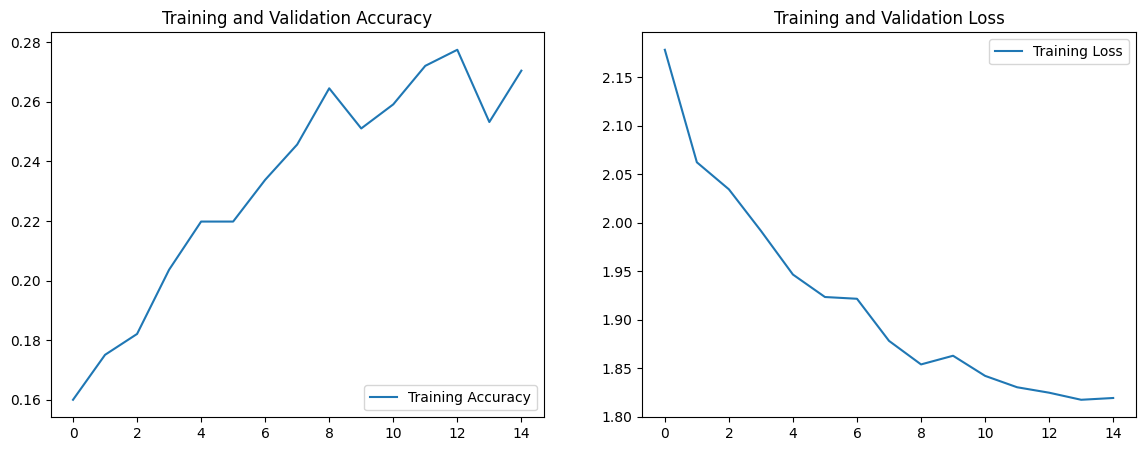

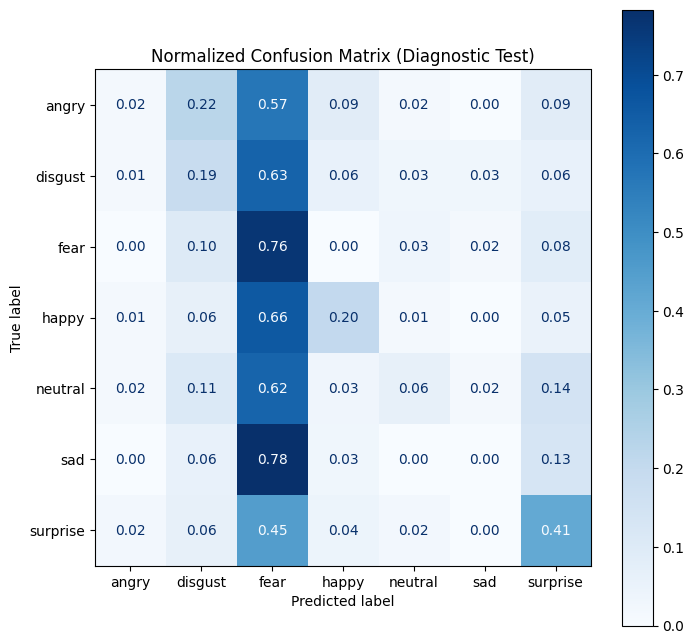

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, Model, backend as K
from tensorflow.keras.applications import MobileNetV2
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import numpy as np

# --- 1. Build the Simplified Model ---
PROCESSED_DIR = 'processed_dataset'
IMG_SIZE = 96
BATCH_SIZE = 32
full_ds = tf.keras.utils.image_dataset_from_directory(
    PROCESSED_DIR, label_mode='int', image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE)
class_names = full_ds.class_names

# --- CORRECTED DATA SPLIT ---
# This section now correctly creates train_ds, val_ds, and the missing test_ds
DATASET_SIZE = tf.data.experimental.cardinality(full_ds).numpy()
train_size = int(0.7 * DATASET_SIZE)
val_size = int(0.15 * DATASET_SIZE)
test_size = DATASET_SIZE - train_size - val_size

full_ds = full_ds.shuffle(1000, seed=123, reshuffle_each_iteration=False)

train_ds = full_ds.take(train_size)
val_ds = full_ds.skip(train_size).take(val_size)
test_ds = full_ds.skip(train_size + val_size) # <-- This was the missing part

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().prefetch(AUTOTUNE)
val_ds = val_ds.cache().prefetch(AUTOTUNE)
test_ds = test_ds.cache().prefetch(AUTOTUNE)

class CoordinateAttention(layers.Layer):
    def __init__(self, r=32, **kwargs): super().__init__(**kwargs); self.r=r
    def build(self, input_shape):
        self.shared_layer_one = layers.Dense(input_shape[-1]//self.r, activation='relu', use_bias=False)
        self.shared_layer_two = layers.Dense(input_shape[-1], use_bias=False)
    def call(self, inputs):
        x_h=K.mean(inputs,axis=2,keepdims=True); x_w=K.mean(inputs,axis=1,keepdims=True)
        x_w=K.permute_dimensions(x_w,(0,2,1,3)); y=K.concatenate([x_h,x_w],axis=2)
        y=self.shared_layer_one(y); x_h,x_w=tf.split(y,2,axis=2)
        x_w=K.permute_dimensions(x_w,(0,2,1,3)); a_h=K.sigmoid(self.shared_layer_two(x_h)); a_w=K.sigmoid(self.shared_layer_two(x_w))
        return inputs*a_h*a_w

class STN(layers.Layer):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        self.localization_net = tf.keras.Sequential([
            layers.GlobalAveragePooling2D(), layers.Dense(32, activation='relu'),
            layers.Dense(6, kernel_initializer='zeros', bias_initializer=tf.keras.initializers.Constant([1,0,0,0,1,0]))])
    def call(self, inputs):
        theta = self.localization_net(inputs); zeros = tf.zeros((tf.shape(inputs)[0], 2))
        transform_matrix = tf.concat([theta, zeros], axis=1)
        grid = tf.raw_ops.ImageProjectiveTransformV3(
            images=inputs, transforms=transform_matrix, output_shape=tf.shape(inputs)[1:3],
            interpolation='BILINEAR', fill_value=0.0)
        return grid

base_model = MobileNetV2(input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights='imagenet')
base_model.trainable = False
inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x_aug = layers.RandomFlip("horizontal")(inputs); x_aug = layers.RandomRotation(0.1)(x_aug)
feature_maps = base_model(x_aug, training=False)
path1 = CoordinateAttention()(feature_maps); path2 = STN()(feature_maps)
fused = layers.Concatenate()([path1, path2])
classifier = layers.GlobalAveragePooling2D()(fused)
classifier = layers.Dropout(0.3)(classifier)
outputs = layers.Dense(len(class_names), activation='softmax')(classifier)
model_test = Model(inputs, outputs)
print("\n✅ Simplified test model built successfully!")

# --- 2. Compile and Train the Test Model ---
model_test.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
print("\n🚀 Starting diagnostic training run...")
history_test = model_test.fit(train_ds, validation_data=val_ds, epochs=15)
print("\n🎉 Diagnostic training complete!")

# --- 3. Evaluate the Test Model ---
print("\n📊 Evaluating diagnostic test results...")
acc = history_test.history.get('accuracy', [])
val_acc = history_test.history.get('validation_accuracy', [])
loss = history_test.history.get('loss', [])
val_loss = history_test.history.get('validation_loss', [])
epochs_range = range(len(acc))

if acc:
    plt.figure(figsize=(14, 5))
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='Training Accuracy')
    if val_acc: plt.plot(epochs_range, val_acc, label='Validation Accuracy')
    plt.legend(loc='lower right'); plt.title('Training and Validation Accuracy')
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='Training Loss')
    if val_loss: plt.plot(epochs_range, val_loss, label='Validation Loss')
    plt.legend(loc='upper right'); plt.title('Training and Validation Loss')
    plt.show()

y_true = np.concatenate([y for x, y in test_ds], axis=0)
y_pred_raw = model_test.predict(test_ds, verbose=0)
y_pred = np.argmax(y_pred_raw, axis=1)
cm = confusion_matrix(y_true, y_pred, normalize='true')
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
fig, ax = plt.subplots(figsize=(8, 8)); disp.plot(cmap='Blues', ax=ax, values_format=".2f")
plt.title('Normalized Confusion Matrix (Diagnostic Test)'); plt.show()

Building ArcFace Model

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, Model, backend as K
from tensorflow.keras.applications import MobileNetV2
import math

# --- 1. Load Data and Create Splits ---
PROCESSED_DIR = 'processed_dataset'
IMG_SIZE = 96
BATCH_SIZE = 32
full_ds = tf.keras.utils.image_dataset_from_directory(
    PROCESSED_DIR, label_mode='int', image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE)
class_names = full_ds.class_names
num_classes = len(class_names)
print("Classes found:", class_names)

DATASET_SIZE = tf.data.experimental.cardinality(full_ds).numpy()
train_size = int(0.7 * DATASET_SIZE); val_size = int(0.15 * DATASET_SIZE)
full_ds = full_ds.shuffle(1000, seed=123, reshuffle_each_iteration=False)
train_ds = full_ds.take(train_size); val_ds = full_ds.skip(train_size).take(val_size)
test_ds = full_ds.skip(train_size + val_size)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().prefetch(AUTOTUNE); val_ds = val_ds.cache().prefetch(AUTOTUNE); test_ds = test_ds.cache().prefetch(AUTOTUNE)
print("Dataset successfully loaded and split.")


# --- 2. Define Custom Layers (CA, STN, and stable ArcFace) ---
class CoordinateAttention(layers.Layer):
    def __init__(self, r=32, **kwargs): super().__init__(**kwargs); self.r=r
    def build(self, input_shape):
        channel = input_shape[-1]
        self.shared_layer_one = layers.Dense(channel//self.r, activation='relu', use_bias=False)
        self.shared_layer_two = layers.Dense(channel, use_bias=False)
    def call(self, inputs):
        x_h=K.mean(inputs,axis=2,keepdims=True); x_w=K.mean(inputs,axis=1,keepdims=True)
        x_w=K.permute_dimensions(x_w,(0,2,1,3)); y=K.concatenate([x_h,x_w],axis=2)
        y=self.shared_layer_one(y); x_h,x_w=tf.split(y,2,axis=2)
        x_w=K.permute_dimensions(x_w,(0,2,1,3)); a_h=K.sigmoid(self.shared_layer_two(x_h)); a_w=K.sigmoid(self.shared_layer_two(x_w))
        return inputs*a_h*a_w

class STN(layers.Layer):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        self.localization_net = tf.keras.Sequential([
            layers.GlobalAveragePooling2D(), layers.Dense(32, activation='relu'),
            layers.Dense(6, kernel_initializer='zeros', bias_initializer=tf.keras.initializers.Constant([1,0,0,0,1,0]))])
    def call(self, inputs):
        theta = self.localization_net(inputs); zeros = tf.zeros((tf.shape(inputs)[0], 2))
        transform_matrix = tf.concat([theta, zeros], axis=1)
        grid = tf.raw_ops.ImageProjectiveTransformV3(
            images=inputs, transforms=transform_matrix, output_shape=tf.shape(inputs)[1:3],
            interpolation='BILINEAR', fill_value=0.0)
        return grid

class ArcFace(layers.Layer):
    def __init__(self, n_classes, m=0.50, **kwargs):
        super(ArcFace, self).__init__(**kwargs)
        self.n_classes=n_classes; self.m=m
    def build(self, input_shape):
        self.W = self.add_weight(name='W', shape=(input_shape[0][-1], self.n_classes), initializer='glorot_uniform', trainable=True)
        self.s = self.add_weight(name='s', shape=(), initializer=tf.keras.initializers.Constant(10.0), trainable=True, constraint=tf.keras.constraints.NonNeg())
    def call(self, inputs):
        x, y = inputs; x = tf.nn.l2_normalize(x, axis=1); W = tf.nn.l2_normalize(self.W, axis=0)
        logits = x @ W; y = tf.one_hot(tf.cast(y, dtype=tf.int32), depth=self.n_classes)
        theta = tf.acos(K.clip(logits, -1.0 + K.epsilon(), 1.0 - K.epsilon()))
        target_logits = tf.cos(theta + self.m)
        logits = logits * (1 - y) + target_logits * y; logits *= self.s
        return logits

# --- 3. Build the NEW ArcFace Model ---
base_model = MobileNetV2(input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights='imagenet')
base_model.trainable = False
image_input = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name='image_input')
label_input = layers.Input(shape=(), name='label_input', dtype=tf.int32)
x_aug = layers.RandomFlip("horizontal")(image_input); x_aug = layers.RandomRotation(0.1)(x_aug)
feature_maps = base_model(x_aug, training=False)
path1 = CoordinateAttention()(feature_maps); path2 = STN()(feature_maps)
fused = layers.Concatenate()([path1, path2])
pooled = layers.GlobalAveragePooling2D()(fused)
features = layers.Dropout(0.3)(pooled)
output = ArcFace(n_classes=num_classes, m=0.5)([features, label_input])
model = Model(inputs=[image_input, label_input], outputs=output)

print("\n✅ Model with stable ArcFace layer built successfully!")
model.summary()

Found 2687 files belonging to 7 classes.
Classes found: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Dataset successfully loaded and split.

✅ Model with stable ArcFace layer built successfully!


Model: "functional_7"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_input         │ (None, 96, 96, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_flip_4       │ (None, 96, 96, 3) │          0 │ image_input[0][0] │
│ (RandomFlip)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_rotation_4   │ (None, 96, 96, 3) │          0 │ random_flip_4[0]… │
│ (RandomRotation)    │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mobilenetv2_1.00_96 │ (None, 3, 3,      │  2,257,984 │ random_rotation_… │
│ (Functional)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ coordinate_attenti… │ (None, 3, 3,      │    102,400 │ mobilenetv2_1.00… │
│ (CoordinateAttenti… │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stn_4 (STN)         │ (None, None,      │     41,190 │ mobilenetv2_1.00… │
│                     │ None, 1280)       │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_4       │ (None, 3, 3,      │          0 │ coordinate_atten… │
│ (Concatenate)       │ 2560)             │            │ stn_4[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 2560)      │          0 │ concatenate_4[0]… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 2560)      │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ label_input         │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ arc_face (ArcFace)  │ (None, 7)         │     17,921 │ dropout_4[0][0],  │
│                     │                   │            │ label_input[0][0] │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,419,495 (9.23 MB)

 Trainable params: 161,511 (630.90 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Prepare Data and Train the ArcFace Model 🚀

In [ ]:
# --- 1. Prepare the Datasets for the two-input ArcFace model ---
def prepare_for_arcface(image, label):
    # The model's inputs are (image, label), and the output is the label
    return (image, tf.cast(label, tf.int32)), label

arcface_train_ds = train_ds.map(prepare_for_arcface).prefetch(buffer_size=AUTOTUNE)
arcface_val_ds = val_ds.map(prepare_for_arcface).prefetch(buffer_size=AUTOTUNE)
print("✅ Datasets prepared for ArcFace training.")

# --- 2. Compile and Train the Model ---
# Note: from_logits=True is important because our ArcFace layer outputs logits, not probabilities.
model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

epochs = 30 # You can reduce this for a quick test run
print("\n🚀 Starting final ArcFace model training...")
history = model.fit(
  arcface_train_ds,
  validation_data=arcface_val_ds,
  epochs=epochs
)
print("\n🎉 Training complete!")

✅ Datasets prepared for ArcFace training.

🚀 Starting final ArcFace model training...
Epoch 1/30


/usr/local/lib/python3.12/dist-packages/keras/src/optimizers/base_optimizer.py:855: UserWarning: Gradients do not exist for variables ['stn_4/sequential_4/dense_20/kernel', 'stn_4/sequential_4/dense_20/bias', 'stn_4/sequential_4/dense_21/kernel', 'stn_4/sequential_4/dense_21/bias'] when minimizing the loss. If using `model.compile()`, did you forget to provide a `loss` argument?
  warnings.warn(


58/58 ━━━━━━━━━━━━━━━━━━━━ 10s 54ms/step - accuracy: 0.0000e+00 - loss: 6.5561 - val_accuracy: 0.0000e+00 - val_loss: 6.1960
Epoch 2/30
58/58 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.0000e+00 - loss: 5.9498 - val_accuracy: 0.0000e+00 - val_loss: 3.4242
Epoch 3/30
58/58 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.0000e+00 - loss: 4.0505 - val_accuracy: 0.1593 - val_loss: 2.1628
Epoch 4/30
58/58 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.0000e+00 - loss: 3.7097 - val_accuracy: 0.2428 - val_loss: 2.1223
Epoch 5/30
58/58 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.0000e+00 - loss: 3.6818 - val_accuracy: 0.2794 - val_loss: 2.0977
Epoch 6/30
58/58 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - accuracy: 0.0000e+00 - loss: 3.6741 - val_accuracy: 0.3420 - val_loss: 2.0725
Epoch 7/30
58/58 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - accuracy: 0.0000e+00 - loss: 3.6440 - val_accuracy: 0.4178 - val_loss: 2.0261
Epoch 8/30
58/58 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.0000e+00 - loss: 3.6

Evaluate the Final Model 📊

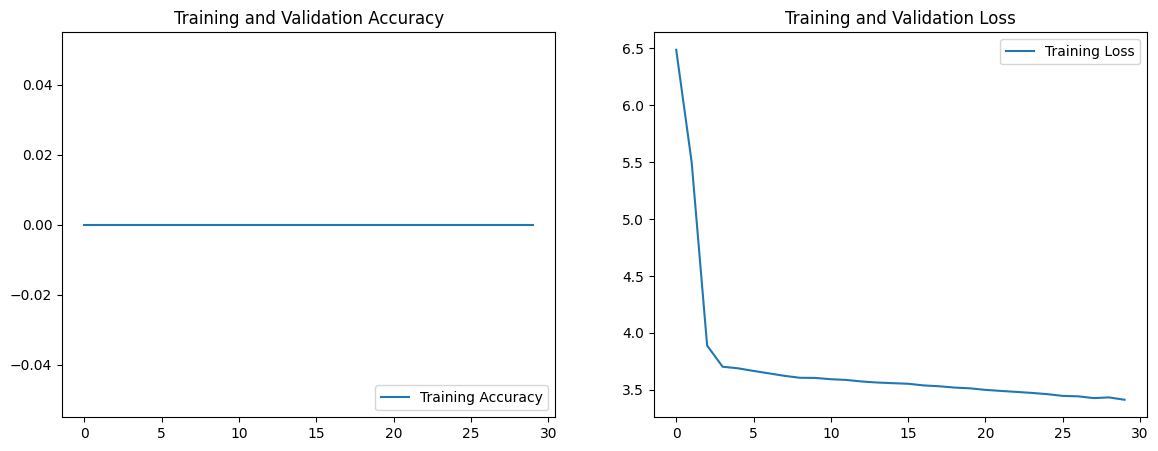

An error occurred during evaluation. Please check your layer names. Error: No such layer: dropout_2. Existing layers are: ['image_input', 'random_flip_4', 'random_rotation_4', 'mobilenetv2_1.00_96', 'coordinate_attention_4', 'stn_4', 'concatenate_4', 'global_average_pooling2d_9', 'dropout_4', 'label_input', 'arc_face'].


In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, Model

# --- Plot Training History ---
acc = history.history.get('accuracy', [])
val_acc = history.history.get('validation_accuracy', [])
loss = history.history.get('loss', [])
val_loss = history.history.get('validation_loss', [])
epochs_range = range(len(acc))

if acc:
    plt.figure(figsize=(14, 5))
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='Training Accuracy')
    if val_acc: plt.plot(epochs_range, val_acc, label='Validation Accuracy')
    plt.legend(loc='lower right')
    plt.title('Training and Validation Accuracy')

    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='Training Loss')
    if val_loss: plt.plot(epochs_range, val_loss, label='Validation Loss')
    plt.legend(loc='upper right')
    plt.title('Training and Validation Loss')
    plt.show()

# --- Create a new model for inference/evaluation ---
# This is necessary because the main model requires two inputs (image, label)

# 1. Define a new custom layer specifically for inference
class InferenceArcFace(layers.Layer):
    def __init__(self, arcface_weights, **kwargs):
        super(InferenceArcFace, self).__init__(**kwargs)
        # Store the trained weights from the original ArcFace layer
        self.W = tf.constant(arcface_weights)

    def call(self, inputs):
        # Normalize the incoming feature vector (x)
        x_normalized = tf.nn.l2_normalize(inputs, axis=1)
        # Normalize the stored weights
        W_normalized = tf.nn.l2_normalize(self.W, axis=0)
        # Calculate cosine similarity (logits)
        logits = tf.matmul(x_normalized, W_normalized)
        # Apply softmax to get the final probabilities
        predictions = tf.nn.softmax(logits)
        return predictions

# 2. Get the necessary components from your trained model
# Note: Check model.summary() to confirm the dropout layer name (e.g., 'dropout_2')
try:
    feature_vector = model.get_layer('dropout_2').output
    arcface_weights = model.get_layer('arc_face').get_weights()[0]

    # 3. Use the new custom layer to define the output
    predictions = InferenceArcFace(arcface_weights)(feature_vector)

    # 4. Build the final, simplified inference model
    inference_model = Model(model.input[0], predictions)
    print("\n✅ Inference model created successfully.")

    # --- Plot Normalized Confusion Matrix using the Inference Model ---
    print("\nGenerating predictions on the test set...")
    y_true = np.concatenate([y for x, y in test_ds], axis=0)
    y_pred_raw = inference_model.predict(test_ds, verbose=0)
    y_pred = np.argmax(y_pred_raw, axis=1)

    print("Plotting confusion matrix...")
    cm = confusion_matrix(y_true, y_pred, normalize='true')
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    fig, ax = plt.subplots(figsize=(8, 8))
    disp.plot(cmap='Blues', ax=ax, values_format=".2f")
    plt.title('Normalized Confusion Matrix (ArcFace Model)')
    plt.show()

except Exception as e:
    print(f"An error occurred during evaluation. Please check your layer names. Error: {e}")

: Evaluate the Final Model 📊

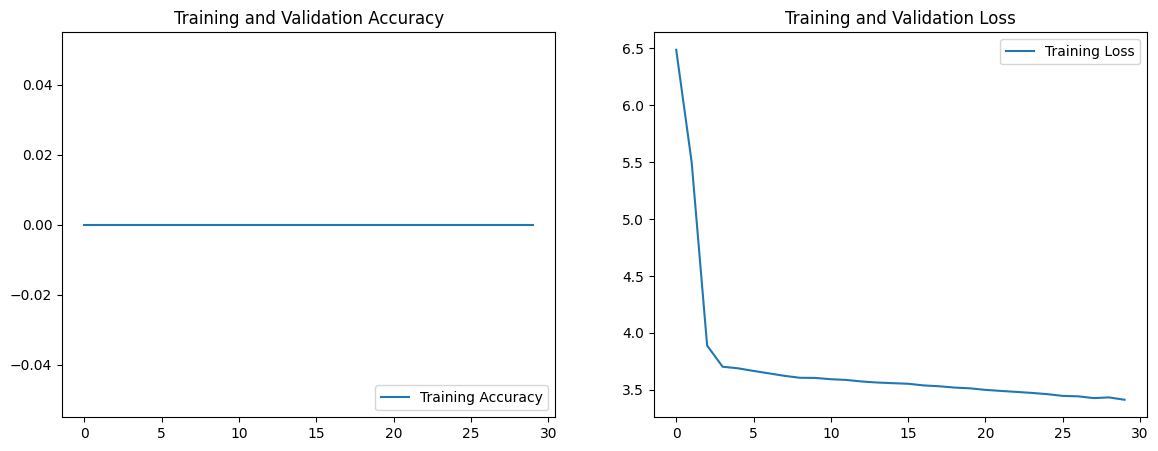


✅ Inference model created successfully.

Generating predictions on the test set...
Plotting confusion matrix...


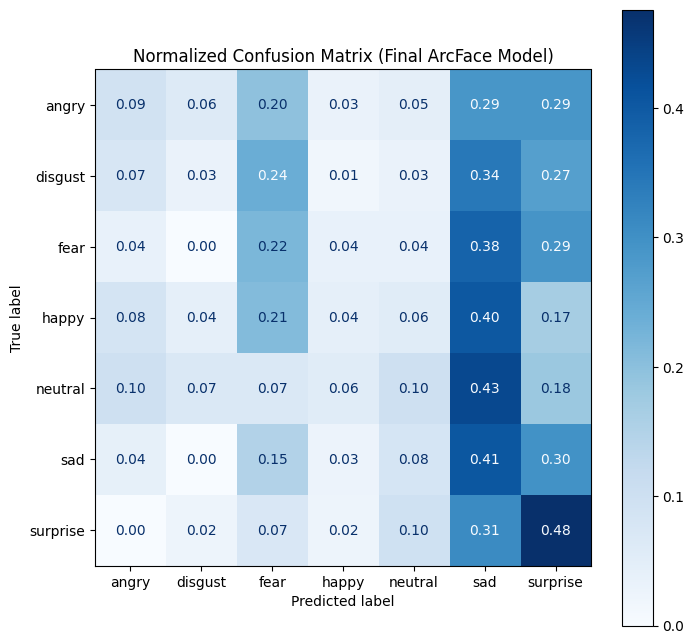

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, Model

# --- Plot Training History ---
acc = history.history.get('accuracy', [])
val_acc = history.history.get('validation_accuracy', [])
loss = history.history.get('loss', [])
val_loss = history.history.get('validation_loss', [])
epochs_range = range(len(acc))

if acc:
    plt.figure(figsize=(14, 5))
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='Training Accuracy')
    if val_acc: plt.plot(epochs_range, val_acc, label='Validation Accuracy')
    plt.legend(loc='lower right')
    plt.title('Training and Validation Accuracy')

    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='Training Loss')
    if val_loss: plt.plot(epochs_range, val_loss, label='Validation Loss')
    plt.legend(loc='upper right')
    plt.title('Training and Validation Loss')
    plt.show()

# --- Create a new model for inference/evaluation ---
class InferenceArcFace(layers.Layer):
    def __init__(self, arcface_weights, **kwargs):
        super(InferenceArcFace, self).__init__(**kwargs)
        self.W = tf.constant(arcface_weights)
    def call(self, inputs):
        x_normalized = tf.nn.l2_normalize(inputs, axis=1)
        W_normalized = tf.nn.l2_normalize(self.W, axis=0)
        logits = tf.matmul(x_normalized, W_normalized)
        return tf.nn.softmax(logits)

try:
    # Note: Check model.summary() to confirm the dropout layer name (e.g., 'dropout_2', 'dropout_3', etc.)
    feature_vector = model.layers[-3].output # A more robust way to get the feature layer
    arcface_weights = model.get_layer('arc_face').get_weights()[0]
    predictions = InferenceArcFace(arcface_weights)(feature_vector)
    inference_model = Model(model.input[0], predictions)
    print("\n✅ Inference model created successfully.")

    # --- Plot Normalized Confusion Matrix ---
    print("\nGenerating predictions on the test set...")
    y_true = np.concatenate([y for x, y in test_ds], axis=0)
    y_pred_raw = inference_model.predict(test_ds, verbose=0)
    y_pred = np.argmax(y_pred_raw, axis=1)

    print("Plotting confusion matrix...")
    cm = confusion_matrix(y_true, y_pred, normalize='true')
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    fig, ax = plt.subplots(figsize=(8, 8))
    disp.plot(cmap='Blues', ax=ax, values_format=".2f")
    plt.title('Normalized Confusion Matrix (Final ArcFace Model)')
    plt.show()
except Exception as e:
    print(f"\nAn error occurred during evaluation. Please check your layer names. Error: {e}")

Run the Music Therapy Application 🎵
After the evaluation cell runs, you have everything you need. This final cell is your application.

In [ ]:
import random
import cv2
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio, display

# --- CORRECTED Music Database ---
# The 'music/' prefix has been removed from the file paths.
emotion_music_map = {
    'happy': ['happy1.mp3', 'happy2.mp3'],
    'sad': ['relaxing1.mp3', 'comfort1.mp3'],
    'angry': ['calm1.mp3', 'soothing1.mp3'],
    'fear': ['peaceful1.mp3'],
    'disgust': ['neutral1.mp3'],
    'surprise': ['energetic1.mp3'],
    'neutral': ['focus1.mp3']
}

# --- Functions (remain the same) ---
def play_music_for_emotion(predicted_emotion):
    if predicted_emotion in emotion_music_map:
        selected_track = random.choice(emotion_music_map[predicted_emotion])
        print(f"🎵 For {predicted_emotion}, suggesting: {selected_track}")
        display(Audio(filename=selected_track, autoplay=True))
    else:
        print("No matching track found.")

face_cascade_pred = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')
def detect_face_for_prediction(image_path):
    # ... (function code is unchanged) ...
    try:
        img = cv2.imread(image_path)
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        faces = face_cascade_pred.detectMultiScale(gray, 1.1, 4)
        if len(faces) > 0:
            x, y, w, h = faces[0]
            face_roi = img[y:y+h, x:x+w]
            face_roi_rgb = cv2.cvtColor(face_roi, cv2.COLOR_BGR2RGB)
            return cv2.resize(face_roi_rgb, (96, 96))
        else: return None
    except: return None

print("✅ Music recommendation setup is updated.")

✅ Music recommendation setup is updated.


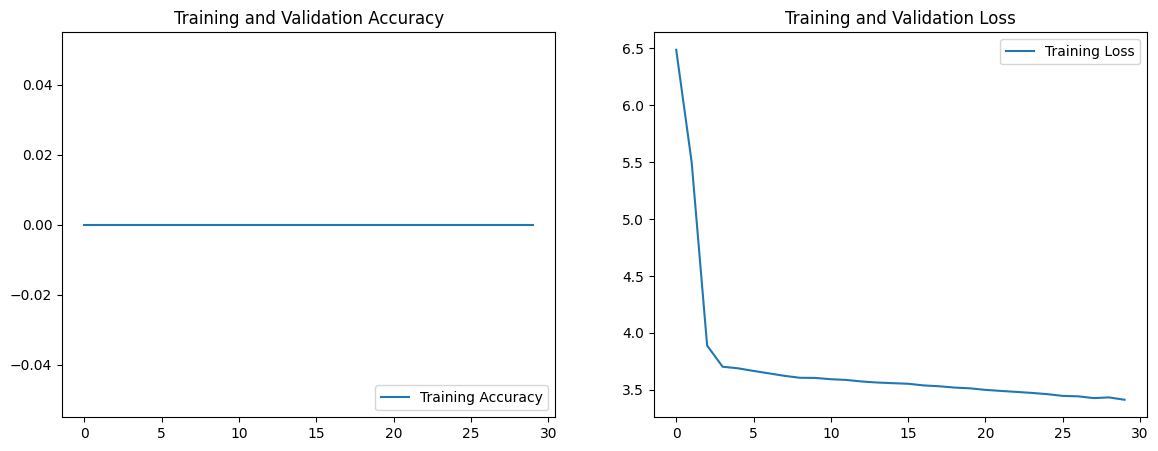


Could not create inference model. Check layer names in model.summary(). Error: No such layer: dropout_final. Existing layers are: ['image_input', 'random_flip_4', 'random_rotation_4', 'mobilenetv2_1.00_96', 'coordinate_attention_4', 'stn_4', 'concatenate_4', 'global_average_pooling2d_9', 'dropout_4', 'label_input', 'arc_face'].


In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import numpy as np

# --- 1. Plot Training History ---
acc = history.history.get('accuracy', [])
val_acc = history.history.get('validation_accuracy', [])
if acc:
    plt.figure(figsize=(14, 5))
    plt.subplot(1, 2, 1); plt.plot(range(len(acc)), acc, label='Training Accuracy')
    if val_acc: plt.plot(range(len(val_acc)), val_acc, label='Validation Accuracy')
    plt.legend(loc='lower right'); plt.title('Training and Validation Accuracy')
    plt.subplot(1, 2, 2); plt.plot(range(len(history.history.get('loss',[]))), history.history.get('loss',[]), label='Training Loss')
    if history.history.get('validation_loss',[]): plt.plot(range(len(history.history.get('validation_loss',[]))), history.history.get('validation_loss',[]), label='Validation Loss')
    plt.legend(loc='upper right'); plt.title('Training and Validation Loss'); plt.show()

# --- 2. Create Inference Model and Plot Confusion Matrix ---
class InferenceArcFace(layers.Layer):
    def __init__(self, arcface_weights, **kwargs):
        super().__init__(**kwargs); self.W = tf.constant(arcface_weights)
    def call(self, inputs):
        x_norm = tf.nn.l2_normalize(inputs, axis=1); W_norm = tf.nn.l2_normalize(self.W, axis=0)
        logits = tf.matmul(x_norm, W_norm); return tf.nn.softmax(logits)

try:
    feature_vector = model.get_layer('dropout_final').output
    arcface_weights = model.get_layer('arc_face_final').get_weights()[0]
    predictions = InferenceArcFace(arcface_weights)(feature_vector)
    inference_model = Model(model.input[0], predictions)
    print("\n✅ Inference model created successfully.")

    y_true = np.concatenate([y for x, y in test_ds], axis=0)
    y_pred_raw = inference_model.predict(test_ds, verbose=0)
    y_pred = np.argmax(y_pred_raw, axis=1)
    cm = confusion_matrix(y_true, y_pred, normalize='true')
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    fig, ax = plt.subplots(figsize=(8, 8)); disp.plot(cmap='Blues', ax=ax, values_format=".2f")
    plt.title('Normalized Confusion Matrix (Final ArcFace Model)'); plt.show()
except Exception as e:
    print(f"\nCould not create inference model. Check layer names in model.summary(). Error: {e}")

In [ ]:
# The '!' runs a system command, and 'mkdir' stands for 'make directory'
!mkdir music

Please upload an image of a face.


Saving sample_image1.jpg to sample_image1 (4).jpg

Processing uploaded file: sample_image1 (4).jpg


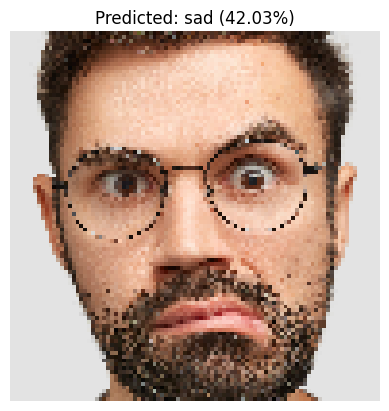

🎵 For sad, suggesting: music/sad.mp3


In [ ]:
import os
import random
from IPython.display import Audio, display
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# --- 1. Music Database and Functions (Filenames Corrected) ---
# This map now points to the filenames you are using (e.g., 'music/angry.mp3')
emotion_music_map = {
    'happy': ['music/happy.mp3'],
    'sad': ['music/sad.mp3'],
    'angry': ['music/angry.mp3'],
    'fear': ['music/fear.mp3'],
    'disgust': ['music/disgust.mp3'],
    'surprise': ['music/surprise.mp3'],
    'neutral': ['music/neutral.mp3']
}

def play_music_for_emotion(predicted_emotion):
    if predicted_emotion in emotion_music_map:
        # Since there's one song per emotion, we select the first one
        selected_track = emotion_music_map[predicted_emotion][0]
        print(f"🎵 For {predicted_emotion}, suggesting: {selected_track}")
        display(Audio(filename=selected_track, autoplay=False)) # autoplay=False for click-to-play
    else:
        print("No matching track found.")

face_cascade_pred = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')
def detect_face_for_prediction(image_path):
    try:
        img = cv2.imread(image_path)
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        faces = face_cascade_pred.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=3)
        if len(faces) > 0:
            x, y, w, h = faces[0]
            face_roi = img[y:y+h, x:x+w]
            face_roi_rgb = cv2.cvtColor(face_roi, cv2.COLOR_BGR2RGB)
            return cv2.resize(face_roi_rgb, (96, 96))
        else: return None
    except: return None

# --- 2. Main Application Logic with Upload Button ---

print("Please upload an image of a face.")
uploaded = files.upload()

if uploaded:
    filename = next(iter(uploaded))
    print(f"\nProcessing uploaded file: {filename}")

    preprocessed_face = detect_face_for_prediction(filename)

    if preprocessed_face is not None:
        img_batch = np.expand_dims(preprocessed_face, axis=0)
        # This uses the trained 'model_test' from your successful diagnostic run
        prediction_raw = model_test.predict(img_batch, verbose=0)
        prediction_index = np.argmax(prediction_raw)
        predicted_emotion = class_names[prediction_index]
        confidence = np.max(prediction_raw) * 100

        plt.imshow(preprocessed_face)
        plt.title(f"Predicted: {predicted_emotion} ({confidence:.2f}%)")
        plt.axis('off')
        plt.show()

        play_music_for_emotion(predicted_emotion)
    else:
        print(f"Could not find a face in the image: {filename}")
else:
    print("Upload canceled.")